# 06. 정부 대책·토허제 전후 가격 변화와 금리 변화의 관계

**질문:** 정부 대책·토허제 지정 전후에 가격은 얼마나 변했는가? 금리 변화와 가격 변화의 관계는 시차·지역별로 어떻게 다른가?

**방법과 지표**
1. **이벤트 달력:** `data/06_정책/`의 대책 목록(21건), 토허제 지정·해제 이력, 조정지역 명세로 노트북 안에서 만든다. 사건마다 날짜 종류(발표일/시행일/미확인)와 그 근거(`date_basis`)를 원자료에 맞춰 적고, 90일 안에 다른 사건이 있으면 겹침으로 표시한다. 날짜 종류가 섞여 있으므로 결과는 "기록된 사건일 이후"의 변화로만 쓰고, 발표에 대한 반응으로 해석하지 않는다.
2. **정부 대책(단순 변화, 사전추세 통제):** 서울 구성 보정 지수(01과 같은 정의, 일괄 제외)에서 기록된 사건일이 속한 달 직전 12개월의 선형 추세를 연장한 값과, 기록된 사건일 이후 3개월째 실제 값의 차이(log×100)를 본다. 같은 계산을 대책이 없는 모든 달에 해서 만든 **위약(placebo) 분포**와 비교한다. 단순 전후 3개월 비교(중위가격·지수)도 참고로 둔다.
3. **토허제(DID):** 지정 동(또는 구)과 미리 정한 인접 미지정 동(구)의 거래로 log(㎡당 가격) ~ 처치×사후 + 단지 FE + 연월 FE + 면적·층 구간을 추정한다. 분기별 이벤트 스터디로 **평행추세(사전 계수)**를 확인하고, 사건일을 12개월 앞당긴 **위약 검정**을 한다. 표준오차는 동(또는 구) 클러스터이며 wild cluster bootstrap p값을 함께 본다.
4. **금리(통계적 연관):** CD(91일) 월평균 변화(%p)와 서울 지수 월 변화율(log×100)의 분포시차 회귀(시차 0~6개월, Newey-West HAC 6시차). 누적 계수와 표준오차를 보고, 국고채 3년물로 민감도를 본다. 02의 가격 급지별, 01의 구별 지수로 같은 회귀를 해 지역 차이를 보고 BH FDR로 보정한다. **금리 자료는 마지막 완결 월(아래에서 계산)까지만 쓴다.**

**사용한 교재 장:** 5장 다중회귀(변형: 이벤트 스터디·DID·분포시차 회귀).
**교재에서 바꾼 점과 이유:** 조율안 06에 따라 교재 기법은 대부분 맞지 않는다. 정책 사건은 21건뿐이라 분류(로지스틱·NB)는 표본이 부족하고, 과열 지역에 지정되는 선택 편의가 있다. 그래서 5장 회귀를 사전추세 반사실·DID·분포시차 회귀로 변형했다. 시계열 자료라 무작위 분할·SMOTE는 쓰지 않는다.

**주의:** 정책 전후 비교는 사전추세를 통제한 **단순 변화**다. DID는 평행추세 가정이 맞을 때만 지정과 함께 나타난 상대 변화로 읽을 수 있고, 여기서는 통계적 연관으로 적는다. 금리 계수는 연관이며 금리는 경기·정책과 함께 움직인다.

**코드 수준:** 계수(크기)만 필요한 단계는 pandas 평균 빼기와 `LinearRegression`으로 쓴 쉬운 함수(`ru.easy_index`, `ru.easy_dong_level` 등)를 쓴다. 원래 함수와 값이 같다(차이 1e-8 이하). 표준오차·검정·부트스트랩이 필요한 단계는 기존 재검증 코드를 그대로 쓴다. 이 노트북에서 쉬운 버전으로 바꾼 곳: 정부 대책·금리 분석에 쓰는 서울 지수. 추세 외삽의 예측 표준오차, 이중차분(단지 클러스터·wild bootstrap), 분포시차 회귀(HAC), FDR 보정은 원래 코드를 쓴다.


In [1]:
import os
import sys
from pathlib import Path


def _find_root():
    env = os.environ.get("REANALYSIS_ROOT")
    if env:
        return Path(env).resolve()
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "AGENTS.md").exists():
            return p
    raise FileNotFoundError("AGENTS.md가 있는 프로젝트 루트를 찾지 못했습니다")


ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src" / "재검증"))
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import reanalysis_utils as ru

SEED = ru.SEED
DATA = ROOT / "data"
plt = ru.set_korean_font()

In [2]:
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from scipy import stats
import openpyxl
import re

OUT = ru.out_dir(ROOT, "06")
POL = DATA / "06_정책"
tx = ru.load_tx(ROOT)
nob = tx[tx["in_base_nobulk"]].reset_index(drop=True)
MONTHS = ru.ym_range("2017-11", "2026-09")

## 1. 이벤트 달력

In [3]:
pol = pd.read_excel(POL / "부동산대책 목록.xlsx")
pol["date"] = pd.to_datetime(pol["시행일자"])


def pol_date_type(name, date, detail):
    """원자료 열 이름은 '시행일자' 하나뿐이다. 대책명의 'M·D'가 이 날짜와 같으면 발표일로, 상세설명이 예정된 시행을 말하면 시행일로, 그 밖에는 미확인으로 둔다."""
    m = re.match(r"^(\d{1,2})·(\d{1,2})", str(name))
    if m and int(m.group(1)) == date.month and int(m.group(2)) == date.day:
        return "발표일", "대책명의 날짜(M·D)가 원자료 '시행일자'와 같음. 관례상 대책명 날짜는 발표일이며, 실제 시행일은 원자료에 없음"
    if any(k in str(detail) for k in ["예정대로", "종료", "시행"]):
        return "시행일", "대책명에 날짜가 없고 상세설명이 예정된 조치의 시행·종료를 적고 있음(원자료 '시행일자')"
    return "미확인", "대책명에 날짜가 없고 상세설명으로도 발표·시행 구분 불가(원자료 '시행일자')"


dt_ = [pol_date_type(n, d_, x) for n, d_, x in zip(pol["대책명"], pol["date"], pol["상세설명"])]
ev = pd.DataFrame({"event_id": [f"P{i + 1:02d}" for i in range(len(pol))], "kind": "정부 대책", "name": pol["대책명"],
                   "date": pol["date"], "date_type": [t[0] for t in dt_], "date_basis": [t[1] for t in dt_], "scope": "전국·서울",
                   "detail": pol["상세설명"]})
lp = pd.read_excel(POL / "서울_토허제_지정해제_이력.xlsx", sheet_name=0)
lp["지정일자"] = pd.to_datetime(lp["지정일자"], errors="coerce")
lp["해제일자"] = pd.to_datetime(lp["해제일자"], errors="coerce")
apt_rows = lp[lp["지정지역(세부)"].str.contains("아파트", na=False)]
apt_rows[["지정구", "지정지역(세부)", "지정일자", "해제일자"]].head(12)

,지정구,지정지역(세부),지정일자,해제일자
5,강남구,삼성·대치·청담동 아파트(국제교류복합지구 인근),2020-06-23,2025-02-13
6,송파구,잠실동 아파트(국제교류복합지구 인근),2020-06-23,2025-02-13
7,강남구,압구정 아파트지구,2021-04-27,NaT
8,영등포구,여의도 아파트지구 및 인근 단지,2021-04-27,NaT
25,강남구,"아파트 전체(구 전역, 잠삼대청 재지정 포함)",2025-03-24,2025-09-30
26,서초구,"아파트 전체(구 전역, 잠삼대청 재지정 포함)",2025-03-24,2025-09-30
27,송파구,"아파트 전체(구 전역, 잠삼대청 재지정 포함)",2025-03-24,2025-09-30
28,용산구,"아파트 전체(구 전역, 잠삼대청 재지정 포함)",2025-03-24,2025-09-30
33,강남구,압구정 아파트지구,2025-04-27,2026-04-26
34,영등포구,여의도 아파트지구 및 인근 단지,2025-04-27,2026-04-26


토허제 이력 가운데 아파트 거래에 직접 걸리는 행(위 표)만 사건으로 쓴다. 자연녹지·그린벨트·도로(사도)·신통기획 후보지 지정은 아파트 거래 대부분과 관계가 없어 달력에는 참고로만 넣고 분석 사건에서 뺀다. 날짜는 이력 파일 범례에 따라 **효력 발생일**이다.

In [4]:
LP_EVENTS = [
    ("L1", "토허제 지정: 강남 삼성·대치·청담, 송파 잠실", "2020-06-23", "강남구 삼성동/대치동/청담동, 송파구 잠실동"),
    ("L2", "토허제 지정: 압구정·여의도·목동·성수", "2021-04-27", "강남구 압구정동, 영등포구 여의도동, 양천구 목동·신정동 일부, 성동구 성수동 일부"),
    ("L3", "토허제 해제: 잠삼대청", "2025-02-13", "강남구 삼성동/대치동/청담동, 송파구 잠실동(재건축 14곳 제외)"),
    ("L4", "토허제 지정: 강남·서초·송파·용산 아파트 전체", "2025-03-24", "강남구·서초구·송파구·용산구 전역 아파트"),
    ("L5", "토허제 지정: 서울 전역 아파트·연립·다세대", "2025-10-20", "서울 25개 구 전역"),
]
ev_lp = pd.DataFrame([{"event_id": e[0], "kind": "토허제", "name": e[1], "date": pd.Timestamp(e[2]), "date_type": "시행일", "date_basis": "이력 파일 범례: 지정일자=효력 발생일, 해제일자=해제일",
                       "scope": e[3], "detail": ""} for e in LP_EVENTS])
wb = openpyxl.load_workbook(POL / "한국주택금융공사_조정지역명세_20261019.xltx", read_only=True)
ws = wb.worksheets[0]
adj = pd.DataFrame(list(ws.iter_rows(values_only=True))[1:], columns=[c.value for c in next(ws.iter_rows(max_row=1))])
adj = adj[adj["법정동명"].astype(str).str.startswith("서울특별시")]
adj_start = adj.groupby(pd.to_datetime(adj["적용시작일자"]).dt.date).size()
ev_adj = pd.DataFrame([{"event_id": f"R{i + 1}", "kind": "규제지역 적용", "name": f"서울 규제지역 적용 시작({n}개 법정동)",
                        "date": pd.Timestamp(dte), "date_type": "시행일", "date_basis": "조정지역 명세의 적용시작일자(현재 유효 지정만 수록)", "scope": "서울 일부 법정동", "detail": ""}
                       for i, (dte, n) in enumerate(adj_start.items())])
cal = pd.concat([ev, ev_lp, ev_adj], ignore_index=True).sort_values("date").reset_index(drop=True)
cal["month"] = cal["date"].dt.strftime("%Y-%m")


def overlaps(row):
    o = cal[(cal["event_id"] != row["event_id"]) & ((cal["date"] - row["date"]).abs().dt.days <= 90)]
    return "; ".join(o["event_id"] + "(" + ((o["date"] - row["date"]).dt.days).astype(str) + "일)")


cal["overlap_90d"] = cal.apply(overlaps, axis=1)
cal["pre_window_cancel_unobserved"] = cal["date"] < pd.Timestamp("2021-02-01")
cal[["event_id", "kind", "name", "date", "date_type", "date_basis", "overlap_90d"]]

,event_id,kind,name,date,date_type,date_basis,overlap_90d
0,P01,정부 대책,6·19 대책,2017-06-19,발표일,대책명의 날짜(M·D)가 원자료 '시행일자'와 같음. 관례상 대책명 날짜는 발표일이...,P02(44일); R1(45일)
1,P02,정부 대책,8·2 대책,2017-08-02,발표일,대책명의 날짜(M·D)가 원자료 '시행일자'와 같음. 관례상 대책명 날짜는 발표일이...,P01(-44일); R1(1일); P03(83일)
2,R1,규제지역 적용,서울 규제지역 적용 시작(73개 법정동),2017-08-03,시행일,조정지역 명세의 적용시작일자(현재 유효 지정만 수록),P01(-45일); P02(-1일); P03(82일)
3,P03,정부 대책,10·24 가계부채 대책,2017-10-24,발표일,대책명의 날짜(M·D)가 원자료 '시행일자'와 같음. 관례상 대책명 날짜는 발표일이...,P02(-83일); R1(-82일)
4,P04,정부 대책,9·13 대책,2018-09-13,발표일,대책명의 날짜(M·D)가 원자료 '시행일자'와 같음. 관례상 대책명 날짜는 발표일이...,P05(8일)
5,P05,정부 대책,9·21 공급대책,2018-09-21,발표일,대책명의 날짜(M·D)가 원자료 '시행일자'와 같음. 관례상 대책명 날짜는 발표일이...,P04(-8일)
6,P06,정부 대책,12·16 대책,2019-12-16,발표일,대책명의 날짜(M·D)가 원자료 '시행일자'와 같음. 관례상 대책명 날짜는 발표일이...,
7,P07,정부 대책,6·17 대책,2020-06-17,발표일,대책명의 날짜(M·D)가 원자료 '시행일자'와 같음. 관례상 대책명 날짜는 발표일이...,L1(6일); P08(23일); P09(48일)
8,L1,토허제,"토허제 지정: 강남 삼성·대치·청담, 송파 잠실",2020-06-23,시행일,"이력 파일 범례: 지정일자=효력 발생일, 해제일자=해제일",P07(-6일); P08(17일); P09(42일)
9,P08,정부 대책,7·10 대책,2020-07-10,발표일,대책명의 날짜(M·D)가 원자료 '시행일자'와 같음. 관례상 대책명 날짜는 발표일이...,P07(-23일); L1(-17일); P09(25일)


`date_type`은 대책명 날짜(M·D)와 원자료 '시행일자'가 같은 대책 20건을 발표일, 예정된 조치의 시행·종료를 적은 대책(예: 양도세 중과 유예 종료)을 시행일, 토허제·규제지역은 효력·적용일이라 시행일로 두었다(근거는 `date_basis`). `overlap_90d`에 다른 사건이 있으면 그 사건과 구간이 겹쳐 따로 떼어 읽을 수 없다. 조정지역 명세 파일에는 **현재 유효한 지정만** 있어 과거 지정·해제 이력은 알 수 없다(적용 시작일 2017-08-03, 2025-10-16 두 날만 나온다). 10·15 대책(목록 2025-10-15)은 규제지역 적용 2025-10-16, 서울 전역 토허제 효력 2025-10-20과 5일 안에 겹친다. `pre_window_cancel_unobserved`는 사전 12개월 구간에 취소 정보가 없는 2020-01 이전 달이 들어가는 사건이다.

## 2. 정부 대책: 사전추세 반사실과 위약 분포

In [5]:
idx, res_idx = ru.easy_index(nob, MONTHS, fe="gu", char_refs=ru.CHAR_REFS)   # 계수만 필요: 쉬운 버전
L = pd.Series(np.log(idx["index"].to_numpy()) * 100, index=idx["month"])
med = nob.groupby("contract_ym")["ppa_manwon"].median().reindex(MONTHS)
LM = np.log(med) * 100
PRE, POST = 12, 3


def trend_gap(m0):
    i0 = MONTHS.index(m0)
    if i0 - PRE < 0 or i0 + POST >= len(MONTHS):
        return None
    xs = np.arange(-PRE, 0)
    ys = L.iloc[i0 - PRE:i0].to_numpy()
    m = sm.OLS(ys, sm.add_constant(xs)).fit()
    pr = m.get_prediction(np.array([[1.0, POST]]))
    pred = float(pr.predicted_mean[0])
    gap = float(L.iloc[i0 + POST]) - pred
    simple_idx = L.iloc[i0 + 1:i0 + POST + 1].mean() - L.iloc[i0 - 3:i0].mean()
    simple_med = LM.iloc[i0 + 1:i0 + POST + 1].mean() - LM.iloc[i0 - 3:i0].mean()
    return {"gap_logpt": gap, "gap_se": float(pr.se_mean[0]), "pre_slope_per_month": float(m.params[1]),
            "simple_index_logpt": simple_idx, "simple_median_logpt": simple_med}


ev_month = set(cal.loc[cal["kind"].isin(["정부 대책", "토허제"]), "month"])
near = set()
for m in ev_month:
    if m in MONTHS:
        i = MONTHS.index(m)
        near.update(MONTHS[max(0, i - 3):i + 4])
plc = pd.DataFrame([{"month": m, **g} for m in MONTHS if m not in near and (g := trend_gap(m)) is not None])
abs_plc = np.abs(plc["gap_logpt"].to_numpy())
rows_e = []
for _, r in cal[cal["kind"].isin(["정부 대책", "토허제"])].iterrows():
    g = trend_gap(r["month"]) if r["month"] in MONTHS else None
    if g is None:
        rows_e.append({"event_id": r["event_id"], "name": r["name"], "month": r["month"], "status": "창 부족(사전 12개월 또는 사후 3개월 없음)"})
        continue
    rows_e.append({"event_id": r["event_id"], "name": r["name"], "month": r["month"], "status": "추정", **g,
                   "placebo_pct_rank_abs": float((abs_plc < abs(g["gap_logpt"])).mean() * 100),
                   "above_placebo_p90": bool(abs(g["gap_logpt"]) > np.percentile(abs_plc, 90)),
                   "overlap_90d": r["overlap_90d"]})
evs = pd.DataFrame(rows_e)
evs["sign_flip_simple_median_vs_index"] = np.sign(evs["simple_median_logpt"]) != np.sign(evs["simple_index_logpt"])
pd.Series({"placebo_months": len(plc), "placebo_abs_gap_p90": np.percentile(abs_plc, 90),
           "placebo_abs_gap_p95": np.percentile(abs_plc, 95)}).round(2)

placebo_months         20.00
placebo_abs_gap_p90    14.60
placebo_abs_gap_p95    15.54
dtype: float64

In [6]:
evs[["event_id", "name", "month", "status", "gap_logpt", "gap_se", "pre_slope_per_month", "placebo_pct_rank_abs", "above_placebo_p90",
     "simple_index_logpt", "simple_median_logpt", "sign_flip_simple_median_vs_index"]].round(2)

,event_id,name,month,status,gap_logpt,gap_se,pre_slope_per_month,placebo_pct_rank_abs,above_placebo_p90,simple_index_logpt,simple_median_logpt,sign_flip_simple_median_vs_index
0,P01,6·19 대책,2017-06,창 부족(사전 12개월 또는 사후 3개월 없음),NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
1,P02,8·2 대책,2017-08,창 부족(사전 12개월 또는 사후 3개월 없음),NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
2,P03,10·24 가계부채 대책,2017-10,창 부족(사전 12개월 또는 사후 3개월 없음),NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
3,P04,9·13 대책,2018-09,창 부족(사전 12개월 또는 사후 3개월 없음),NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
4,P05,9·21 공급대책,2018-09,창 부족(사전 12개월 또는 사후 3개월 없음),NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
5,P06,12·16 대책,2019-12,추정,-9.77,1.31,1.87,75.0,False,0.84,-13.46,True
6,P07,6·17 대책,2020-06,추정,10.79,1.09,0.55,75.0,False,13.14,23.12,False
7,L1,"토허제 지정: 강남 삼성·대치·청담, 송파 잠실",2020-06,추정,10.79,1.09,0.55,75.0,False,13.14,23.12,False
8,P08,7·10 대책,2020-07,추정,7.09,1.99,0.82,55.0,False,10.82,18.01,False
9,P09,8·4 공급대책,2020-08,추정,8.46,2.42,1.08,65.0,False,8.55,12.35,False


- `gap_logpt`: 기록된 사건일 이후 3개월째 지수가 사전 12개월 추세 연장값보다 높거나 낮은 정도(log×100). `gap_se`는 추세 연장값의 표준오차다(지수 자체의 추정 오차는 포함하지 않음).
- `placebo_pct_rank_abs`: 사건이 없는 달(사건 ±3개월 제외)에서 같은 계산을 한 |gap| 분포 안에서 이 사건의 |gap|이 몇 백분위인지. `above_placebo_p90`은 |gap|을 위약 |gap| 분포의 90백분위(`np.percentile`, 선형 보간)와 직접 비교한 결과다. 위약 달이 20개뿐이라 백분위 순위(정수 단위)와 보간된 90백분위 비교가 경계에서 다를 수 있어, 요약 수치는 직접 비교 기준으로 센다.
- `simple_index_logpt`/`simple_median_logpt`: 사건 전 3개월 대비 후 3개월 평균의 단순 차이(지수/중위가격). `sign_flip…`이 True면 중위가격과 보정 지수의 방향이 반대다(거래 구성 변화 때문).

In [7]:
es_rows = []
for _, r in evs[evs["status"] == "추정"].iterrows():
    i0 = MONTHS.index(r["month"])
    xs = np.arange(-PRE, 0)
    m = sm.OLS(L.iloc[i0 - PRE:i0].to_numpy(), sm.add_constant(xs)).fit()
    base = L.iloc[i0 - 1]
    for k in range(-PRE, 7):
        if 0 <= i0 + k < len(MONTHS):
            es_rows.append({"event_id": r["event_id"], "rel_month": k, "month": MONTHS[i0 + k],
                            "actual_logpt": float(L.iloc[i0 + k] - base),
                            "pre_trend_logpt": float(m.params[0] + m.params[1] * k - base)})
es = pd.DataFrame(es_rows)


## 3. 토허제 DID와 이벤트 스터디

처치군은 이력 파일에 적힌 실제 적용 대상으로 구성하고, 보유 자료로 대상을 정확히 가를 수 없는 사건은 **"지역 단위 대리 비교"**로 표시한다. 대리 비교 결과는 실제 정책 대상의 가격 변화로 읽지 않는다.

설계(결과를 보기 전에 고정). 모든 사건에서 창 기간 동안 다른 토허제 지정(아파트·정비구역)이 걸린 동은 처치·대조 양쪽에서 뺀다(아래 `table_lp_prior_designations.csv`).
| 사건 | 비교 유형 | 처치군 | 대조군 | 사전 구간 | 사후 구간 | 제외 | 클러스터 |
|---|---|---|---|---|---|---|---|
| L1 2020-06-23 지정 | 정책 대상 비교(대상=해당 4개 동 아파트 전체) | 강남 삼성·대치·청담, 송파 잠실 | 강남·서초·송파의 나머지 동 | 2019-06-23~2020-06-16 | 2020-06-23~2021-04-26 | 6·17 발표~효력 전(06-17~06-22) | 동 |
| L2-목동 2021-04-27 지정 | 정책 대상 비교(부분: 목동 택지개발지구 중 이름으로 식별되는 목동신시가지 1~14단지) | 목동신시가지 1~14단지(단지 단위) | 양천구 신월동·강서구 단지 | 2020-04-27~2021-04-26 | 2021-04-27~2022-04-26 | 목동·신정동의 나머지 단지(지구 경계를 알 수 없어 양쪽에서 제외) | 단지 |
| L2-압구정·여의도 2021-04-27 지정 | **지역 단위 대리 비교**(아파트지구 경계 자료 없음, 동 전체로 대신함) | 강남 압구정동, 영등포 여의도동 | 강남·영등포의 나머지 동 | 같음 | 같음 | 잠삼대청(이미 지정) | 동 |
| L3 2025-02-13 해제 | **지역 단위 대리 비교**(계속 지정된 재건축 14개 단지의 이름이 원자료에 없어 제외 불가) | 강남 삼성·대치·청담, 송파 잠실 | 강남·서초·송파의 나머지 동 | 2024-08-13~2025-02-12 | 2025-02-13~2025-03-23 | 압구정동(계속 지정) | 동 |
| L4 2025-03-24 지정 | 정책 대상 비교(대상=4개 구 아파트 중 새로 지정된 부분) | 강남·서초·송파·용산에서 창 기간에 이미 지정돼 있던 동(잠삼대청·압구정·용산 정비창 일대 이촌동·한강로1~3가·원효로4가)을 뺀 나머지 | 인접 구: 성동·광진·강동·동작·마포·중구·관악(이미 지정된 성수동1·2가 제외) | 2024-03-24~2025-02-12 | 2025-03-24~2025-06-26 | 2025-02-13~03-23(L3 해제 구간) | 구 |

- 성수 전략정비구역(L2)은 구역 경계를 자료로 가를 수 없어 분석하지 않는다.
- L3 민감도: 처치 동에서 2025년 기준 연식 30년 이상 단지(건축년도 1995년 이전, 재건축 단지일 가능성이 큰 단지)를 뺀 대리 비교도 둔다. 이 역시 재건축 14개 단지를 정확히 뺀 것이 아니다.
- L4의 사후 구간은 6·27 대책(대출 한도) 전날까지로 잘랐다. 9월 말까지 늘린 결과는 민감도로 둔다.
- L5(2025-10-20 서울 전역)는 서울 안에 대조군이 없어 DID를 하지 않고 2절의 사전추세 비교로만 본다.
- L3의 재지정 발표일은 원자료에 없어 효력일(03-24) 전날까지를 사후 구간으로 썼다.

In [8]:
def ids(pairs):
    return {f"{g} {d}" for g, ds in pairs for d in ds}


JSDC = ids([("강남구", ["삼성동", "대치동", "청담동"]), ("송파구", ["잠실동"])])
APYD = ids([("강남구", ["압구정동"]), ("영등포구", ["여의도동"])])
APGU = ids([("강남구", ["압구정동"])])
MOK_DONGS = ids([("양천구", ["목동", "신정동"])])
mk = nob[nob["dong_id"].isin(MOK_DONGS)][["complex_id", "complex_name"]].drop_duplicates()
mk["sinsi_no"] = mk["complex_name"].str.extract(r"^목동신시가지(\d+)$")[0]
MOK_SINSI = set(mk.loc[mk["sinsi_no"].notna(), "complex_id"])
sinsi_matched = sorted(int(x) for x in mk["sinsi_no"].dropna().astype(int).unique())
match_tab = pd.DataFrame([
    {"event": "L2-목동", "target": "목동 택지개발지구(목동신시가지 1~14단지)", "target_units": 14, "matched_units": len(sinsi_matched),
     "note": f"단지명 '목동신시가지N'으로 매칭, 번호 {sinsi_matched}, 단지 키 {len(MOK_SINSI)}개(같은 단지의 건축년도 표기 차이 포함)"},
    {"event": "L3", "target": "해제 대상에서 빠진 잠삼대청 재건축 14개 단지", "target_units": 14, "matched_units": 0,
     "note": "이력 파일에 단지명이 없어 거래와 매칭할 수 없음 → 지역 단위 대리 비교"},
    {"event": "L2-압구정·여의도", "target": "압구정 아파트지구, 여의도 아파트지구 및 인근 단지", "target_units": np.nan, "matched_units": np.nan,
     "note": "지구 경계·단지 목록이 원자료에 없음 → 동 전체로 대신한 지역 단위 대리 비교"},
])
match_tab

,event,target,target_units,matched_units,note
0,L2-목동,목동 택지개발지구(목동신시가지 1~14단지),14.0,14.0,"단지명 '목동신시가지N'으로 매칭, 번호 [1, 2, 3, 4, 5, 6, 7, 8..."
1,L3,해제 대상에서 빠진 잠삼대청 재건축 14개 단지,14.0,0.0,이력 파일에 단지명이 없어 거래와 매칭할 수 없음 → 지역 단위 대리 비교
2,L2-압구정·여의도,"압구정 아파트지구, 여의도 아파트지구 및 인근 단지",NaN,NaN,지구 경계·단지 목록이 원자료에 없음 → 동 전체로 대신한 지역 단위 대리 비교


In [9]:
def old_cx(w):
    return w["build_year"] <= 1995


# 원자료 토허제 이력의 '지정지역(세부)' → (종류, 거래 자료의 dong_id). 경계가 동보다 작아도 해당 동 전체를 보수적으로 매핑한다.
YS = ["이촌동", "한강로1가", "한강로2가", "한강로3가"]
APT_KIND, GREEN_KIND = "아파트·정비구역", "자연녹지·그린벨트·취락"
PRIOR_MAP = {
    "삼성·대치·청담동 아파트(국제교류복합지구 인근)": (APT_KIND, ["강남구 삼성동", "강남구 대치동", "강남구 청담동"]),
    "잠실동 아파트(국제교류복합지구 인근)": (APT_KIND, ["송파구 잠실동"]),
    "재건축 단지(대치·삼성·청담동, 잠삼대청 재건축 14곳 중)": (APT_KIND, ["강남구 삼성동", "강남구 대치동", "강남구 청담동"]),
    "재건축 단지(잠실동, 잠삼대청 재건축 14곳 중)": (APT_KIND, ["송파구 잠실동"]),
    "압구정 아파트지구": (APT_KIND, ["강남구 압구정동"]),
    "여의도 아파트지구 및 인근 단지": (APT_KIND, ["영등포구 여의도동"]),
    "목동 택지개발지구": (APT_KIND, ["양천구 목동", "양천구 신정동"]),
    "성수 전략정비구역 1~4구역": (APT_KIND, ["성동구 성수동1가", "성동구 성수동2가"]),
    "용산 정비창 부지 및 한강로동·서부이촌동 정비사업구역 13곳(0.77㎢)": (APT_KIND, ["용산구 " + x for x in YS]),
    "용산 정비창 및 인근 정비사업구역(연장)": (APT_KIND, ["용산구 " + x for x in YS]),
    "정비창 일대 0.72㎢(이촌동·한강로1~3가·용산동3가·원효로4가)": (APT_KIND, ["용산구 " + x for x in YS + ["용산동3가", "원효로4가"]]),
    "이촌동·한강로3가 일부(0.02㎢)": (APT_KIND, ["용산구 이촌동", "용산구 한강로3가"]),
    "자연녹지(수서·개포·세곡·율현·자곡·일원동 등)": (GREEN_KIND, ["강남구 " + x for x in ["수서동", "개포동", "세곡동", "율현동", "자곡동", "일원동"]]),
    "자연녹지(수서·개포·세곡·율현·자곡·일원·대치동)": (GREEN_KIND, ["강남구 " + x for x in ["수서동", "개포동", "세곡동", "율현동", "자곡동", "일원동", "대치동"]]),
    "자연녹지(수서·개포·세곡·율현·자곡·일원·대치동, 수서역세권·구룡마을 인근)": (GREEN_KIND, ["강남구 " + x for x in ["수서동", "개포동", "세곡동", "율현동", "자곡동", "일원동", "대치동"]]),
    "자연녹지(방배(성뒤마을)·내곡·신원·염곡·원지·우면·서초·양재동)": (GREEN_KIND, ["서초구 " + x for x in ["방배동", "내곡동", "신원동", "염곡동", "원지동", "우면동", "서초동", "양재동"]]),
    "자연녹지(양재·우면·방배·내곡·신원·염곡·원지·서초동)": (GREEN_KIND, ["서초구 " + x for x in ["방배동", "내곡동", "신원동", "염곡동", "원지동", "우면동", "서초동", "양재동"]]),
    "자연녹지(양재·우면·방배(성뒤마을)·내곡·신원·염곡·원지·서초동)": (GREEN_KIND, ["서초구 " + x for x in ["방배동", "내곡동", "신원동", "염곡동", "원지동", "우면동", "서초동", "양재동"]]),
    "서리풀 일대 우면동·신원동 집단취락지구 약 7만㎡": (GREEN_KIND, ["서초구 우면동", "서초구 신원동"]),
    "수서역세권 일대 일부 0.67㎢": (GREEN_KIND, ["강남구 수서동"]),
}
ALL_DONGS = set(nob["dong_id"].unique())


def map_row(r):
    txt = str(r["지정지역(세부)"])
    if txt in PRIOR_MAP:
        return PRIOR_MAP[txt]
    if "구 전역" in txt and str(r["지정구"]).endswith("구"):
        return ("구 전체 아파트", sorted(d_ for d_ in ALL_DONGS if d_.startswith(str(r["지정구"]) + " ")))
    return ("기타(토지·도로·후보지·위치 미상)", [])


def prior_rows(spec):
    """사건 창(사전 시작~사후 끝) 동안 유효했던 다른 지정 이력. 사건 자신(지정일 또는 해제일이 사건일과 같은 행)은 뺀다."""
    t = pd.Timestamp(spec["date"])
    a, e = pd.Timestamp(spec["pre"][0]), pd.Timestamp(spec["post"][1])
    st = lp["지정일자"].fillna(pd.Timestamp("1900-01-01"))
    en = lp["해제일자"].fillna(pd.Timestamp("2100-01-01"))
    act = lp[(st <= e) & (en >= a) & ~((lp["지정일자"] == t) | (lp["해제일자"] == t))].copy()
    km = act.apply(map_row, axis=1)
    act["kind"] = [k for k, _ in km]
    act["dong_ids"] = [d_ for _, d_ in km]
    return act


DID = {
    "L1": dict(date="2020-06-23", pre=("2019-06-23", "2020-06-16"), post=("2020-06-23", "2021-04-26"),
               treat=lambda w: w["dong_id"].isin(JSDC), ctrl=lambda w: w["gu"].isin(["강남구", "서초구", "송파구"]),
               cluster="dong_id", comparison="정책 대상 비교", target="해당 4개 동 아파트 전체(동 단위로 대상 일치)"),
    "L2-목동": dict(date="2021-04-27", pre=("2020-04-27", "2021-04-26"), post=("2021-04-27", "2022-04-26"),
                  treat=lambda w: w["complex_id"].isin(MOK_SINSI),
                  ctrl=lambda w: (w["dong_id"] == "양천구 신월동") | (w["gu"] == "강서구"),
                  cluster="complex_id", comparison="정책 대상 비교(부분)", target="목동신시가지 1~14단지(단지 단위, 지구의 다른 단지는 미식별)"),
    "L2-압구정·여의도": dict(date="2021-04-27", pre=("2020-04-27", "2021-04-26"), post=("2021-04-27", "2022-04-26"),
                       treat=lambda w: w["dong_id"].isin(APYD),
                       ctrl=lambda w: w["gu"].isin(["강남구", "영등포구"]),
                       cluster="dong_id", comparison="지역 단위 대리 비교", target="압구정동·여의도동 전체(아파트지구 경계 미식별)"),
    "L3": dict(date="2025-02-13", pre=("2024-08-13", "2025-02-12"), post=("2025-02-13", "2025-03-23"),
               treat=lambda w: w["dong_id"].isin(JSDC), ctrl=lambda w: w["gu"].isin(["강남구", "서초구", "송파구"]),
               cluster="dong_id", comparison="지역 단위 대리 비교", target="잠삼대청 4개 동 전체(계속 지정된 재건축 14개 단지 미식별)"),
    "L3-노후제외": dict(date="2025-02-13", pre=("2024-08-13", "2025-02-12"), post=("2025-02-13", "2025-03-23"),
                     treat=lambda w: w["dong_id"].isin(JSDC) & ~old_cx(w),
                     ctrl=lambda w: w["gu"].isin(["강남구", "서초구", "송파구"]) & ~w["dong_id"].isin(JSDC),
                     cluster="dong_id", comparison="지역 단위 대리 비교", target="잠삼대청 4개 동에서 1995년 이전 준공 단지 제외(재건축 14개 단지 대신)"),
    "L4": dict(date="2025-03-24", pre=("2024-03-24", "2025-02-12"), post=("2025-03-24", "2025-06-26"),
               treat=lambda w: w["gu"].isin(["강남구", "서초구", "송파구", "용산구"]),
               ctrl=lambda w: w["gu"].isin(["성동구", "광진구", "강동구", "동작구", "마포구", "중구", "관악구"]),
               cluster="gu", comparison="정책 대상 비교",
               target="4개 구 아파트 중 기존 지정이 없던 동(잠삼대청·압구정·용산 정비창 일대 동 제외), 대조 구도 기존 지정 동(성수동1·2가) 제외"),
}
DID["L4_long"] = dict(DID["L4"], post=("2025-03-24", "2025-09-30"))
# 민감도: 자연녹지·그린벨트·취락 지정이 걸린 동까지 보수적으로 제외
for k_ in ["L1", "L3", "L4"]:
    DID[k_ + "-녹지동제외"] = dict(DID[k_], green_excl=True, target=DID[k_]["target"] + " + 자연녹지·취락 지정 동 제외")
# 민감도: 기존 지정 지역을 처치군에 남긴 이전 사양(용산 정비창 일대 포함) → 대상이 섞여 지역 단위 대리 비교
DID["L4-기존지정포함"] = dict(DID["L4"], keep_prior_in_treat_gu=["용산구"], comparison="지역 단위 대리 비교",
                          target="4개 구 아파트(용산 정비창 일대 기존 지정 동 포함, 이전 사양)")
ES_EVENTS = ["L1", "L2-목동", "L2-압구정·여의도", "L3", "L4"]
NO_PLACEBO = {"L4_long", "L3-노후제외", "L1-녹지동제외", "L3-녹지동제외", "L4-녹지동제외", "L4-기존지정포함"}

prior_tabs = []
EXCL = {}
for name, spec in DID.items():
    pr = prior_rows(spec)
    apt = set(d_ for k_, ds in zip(pr["kind"], pr["dong_ids"]) if k_ in (APT_KIND, "구 전체 아파트") for d_ in ds)
    green = set(d_ for k_, ds in zip(pr["kind"], pr["dong_ids"]) if k_ == GREEN_KIND for d_ in ds)
    keep_gu = spec.get("keep_prior_in_treat_gu", [])
    apt_used = {d_ for d_ in apt if not any(d_.startswith(g + " ") for g in keep_gu)}
    if keep_gu:  # 이전 사양 재현: 잠삼대청·압구정만 제외
        apt_used = {d_ for d_ in apt if d_ in JSDC | APGU}
    EXCL[name] = apt_used | (green if spec.get("green_excl") else set())
    if name in ["L1", "L2-목동", "L2-압구정·여의도", "L3", "L4"]:
        for _, r in pr.iterrows():
            in_tx = [d_ for d_ in r["dong_ids"] if d_ in ALL_DONGS]
            prior_tabs.append({"event": name, "row": int(r.name), "지정구": r["지정구"], "지정지역": r["지정지역(세부)"],
                               "start": str(r["지정일자"].date()) if pd.notna(r["지정일자"]) else "미확인",
                               "end": str(r["해제일자"].date()) if pd.notna(r["해제일자"]) else "미정·진행",
                               "kind": r["kind"], "mapped_dongs": "; ".join(r["dong_ids"]), "dongs_in_tx": len(in_tx),
                               "use": ("주 사양에서 처치·대조 모두 제외" if r["kind"] in (APT_KIND, "구 전체 아파트") and r["dong_ids"]
                                       else ("민감도(녹지동제외)에서 제외" if r["kind"] == GREEN_KIND else "아파트 거래와 대부분 무관해 반영 안 함"))})
prior_tab = pd.DataFrame(prior_tabs)
prior_tab[["event", "row", "지정구", "지정지역", "start", "end", "kind", "dongs_in_tx", "use"]]

,event,row,지정구,지정지역,start,end,kind,dongs_in_tx,use
0,L1,2,강남구,자연녹지(수서·개포·세곡·율현·자곡·일원동 등),2018-05-31,2021-05-30,자연녹지·그린벨트·취락,6,민감도(녹지동제외)에서 제외
1,L1,3,서초구,자연녹지(방배(성뒤마을)·내곡·신원·염곡·원지·우면·서초·양재동),2018-05-31,2021-05-30,자연녹지·그린벨트·취락,6,민감도(녹지동제외)에서 제외
2,L1,4,용산구,용산 정비창 부지 및 한강로동·서부이촌동 정비사업구역 13곳(0.77㎢),2020-05-20,2021-05-19,아파트·정비구역,4,주 사양에서 처치·대조 모두 제외
3,L1,17,용산구,이촌동·한강로3가 일부(0.02㎢),미확인,2024-05-20,아파트·정비구역,2,주 사양에서 처치·대조 모두 제외
4,L1,21,강남구,수서역세권 일대 일부 0.67㎢,미확인,2024-12-04,자연녹지·그린벨트·취락,1,민감도(녹지동제외)에서 제외
...,...,...,...,...,...,...,...,...,...
75,L4,37,강남구,자연녹지(수서·개포·세곡·율현·자곡·일원·대치동),2025-05-31,2026-05-30,자연녹지·그린벨트·취락,7,민감도(녹지동제외)에서 제외
76,L4,38,서초구,자연녹지(양재·우면·방배·내곡·신원·염곡·원지·서초동),2025-05-31,2026-05-30,자연녹지·그린벨트·취락,6,민감도(녹지동제외)에서 제외
77,L4,39,미특정(서울시),신통기획 재개발 선정지 11곳,2025-06-04,미정·진행,기타(토지·도로·후보지·위치 미상),0,아파트 거래와 대부분 무관해 반영 안 함
78,L4,40,강남구,"재건축 단지(대치·삼성·청담동, 잠삼대청 재건축 14곳 중)",2025-06-23,2026-06-22,아파트·정비구역,3,주 사양에서 처치·대조 모두 제외


위 표는 사건별 DID 창(사전 시작~사후 끝) 동안 유효했던 **다른** 토허제 지정 이력이다(사건 자신 제외). 아파트·정비구역 지정은 경계를 동 안에서 가를 수 없으므로 해당 법정동 전체를 처치군·대조군 **양쪽에서** 뺀다(주 사양). 자연녹지·그린벨트·취락 지정은 아파트 단지가 거의 없는 땅이라 주 사양에는 두고, 그 동까지 빼는 민감도(`-녹지동제외`)를 따로 낸다. 도로(사도)·후보지·위치 미상 지정은 반영하지 않는다. 용산 정비창 일대(이촌동·한강로1~3가·용산동3가·원효로4가, 2024-05-20~2025-12-31)는 L4 창 전체에 걸쳐 이미 지정돼 있었으므로 L4 처치군에서 뺐다(이전 사양은 `L4-기존지정포함`, 지역 단위 대리 비교로 남김). 용산동3가는 거래 자료에 없다.

In [10]:
def window(spec, name, shift_days=0):
    sh = pd.Timedelta(days=shift_days)
    a, b = pd.Timestamp(spec["pre"][0]) - sh, pd.Timestamp(spec["pre"][1]) - sh
    c, e = pd.Timestamp(spec["post"][0]) - sh, pd.Timestamp(spec["post"][1]) - sh
    w = nob[((nob["contract_date"] >= a) & (nob["contract_date"] <= b)) | ((nob["contract_date"] >= c) & (nob["contract_date"] <= e))]
    w = w[~w["dong_id"].isin(EXCL[name])].copy()
    w["treat"] = spec["treat"](w)
    w["ctrl"] = spec["ctrl"](w) & ~w["treat"]
    if name.startswith("L2-압구정"):
        w["ctrl"] &= ~w["dong_id"].isin(APYD)
    w = w[w["treat"] | w["ctrl"]].reset_index(drop=True)
    w["post"] = w["contract_date"] >= c
    # 사건일 기준 3개월(DateOffset) 경계로 상대 분기를 만든다. 창 경계에서 잘린 분기는 불완전으로 표시한다.
    w["rel_q"] = np.nan
    bins = []
    for k in range(-8, 8):
        bs, be = c + pd.DateOffset(months=3 * k), c + pd.DateOffset(months=3 * (k + 1))
        m = (w["contract_date"] >= bs) & (w["contract_date"] < be)
        w.loc[m, "rel_q"] = k
        if m.any():
            bins.append({"rel_q": k, "bin_start": str(bs.date()), "bin_end_excl": str(be.date()),
                         "complete": bool(bs >= a and be <= e + pd.Timedelta(days=1))})
    bins = pd.DataFrame(bins)
    w["rel_q"] = w["rel_q"].astype(int)
    w["bin_complete"] = w["rel_q"].map(bins.set_index("rel_q")["complete"])
    return w, bins


def did_fit(w, cluster, event_study=False):
    if event_study:
        w = w[w["bin_complete"]].reset_index(drop=True)
    chars = ru.dummies(w, ru.CHAR_REFS_NOAGE).reset_index(drop=True)
    if event_study:
        qs = sorted(set(w["rel_q"]) - {-1})
        Xe = pd.DataFrame({f"q{q}": ((w["rel_q"] == q) & w["treat"]).astype(float) for q in qs})
        X = pd.concat([Xe, chars], axis=1)
    else:
        X = pd.concat([pd.DataFrame({"did": (w["treat"] & w["post"]).astype(float)}), chars], axis=1)
    return ru.fe_ols(w["log_ppa"].to_numpy(), X, [w["complex_id"].to_numpy(), w["contract_ym"].to_numpy()],
                     clusters=w[cluster].to_numpy())


did_rows, es_did, bin_rows = [], [], []
for name, spec in DID.items():
    for shift, lab in [(0, "실제"), (365, "위약(-12개월)")]:
        if name in NO_PLACEBO and shift:
            continue
        w, bins = window(spec, name, shift)
        r = did_fit(w, spec["cluster"])
        ct = ru.coef_table(r).set_index("term").loc["did"]
        pb, _ = ru.wild_cluster_boot_p(r, "did", w[spec["cluster"]].to_numpy(), B=999)
        did_rows.append({"event": name, "type": lab, "comparison": spec["comparison"], "target": spec["target"],
                         "excluded_prior_dongs": "; ".join(sorted(d_ for d_ in EXCL[name] if d_ in ALL_DONGS)),
                         "coef": ct["coef"], "pct": (np.exp(ct["coef"]) - 1) * 100, "se": ct["se"],
                         "p_cluster": ct["p_value"], "wild_boot_p": pb, "ci_low_pct": (np.exp(ct["ci_low"]) - 1) * 100,
                         "ci_high_pct": (np.exp(ct["ci_high"]) - 1) * 100, "n": r["n"], "n_treat_tx": int(w["treat"].sum()),
                         "n_clusters": r["n_clusters"], "n_treat_clusters": int(w.loc[w["treat"], spec["cluster"]].nunique()),
                         "pre_start": str((pd.Timestamp(spec["pre"][0]) - pd.Timedelta(days=shift)).date()),
                         "post_end": str((pd.Timestamp(spec["post"][1]) - pd.Timedelta(days=shift)).date())})
        if shift == 0 and name in ES_EVENTS:
            cnt = w.groupby("rel_q").agg(n_tx=("row_id", "size"), n_treat_tx=("treat", "sum"))
            cnt["n_treat_clusters"] = w[w["treat"]].groupby("rel_q")[spec["cluster"]].nunique()
            bins = bins.merge(cnt.reset_index(), on="rel_q", how="left").fillna({"n_treat_clusters": 0})
            bins["event"] = name
            bin_rows.append(bins)
            re_ = did_fit(w, spec["cluster"], event_study=True)
            cte = ru.coef_table(re_)
            leads = [t for t in cte["term"] if t.startswith("q-")]
            b = re_["beta"][leads].to_numpy()
            V = re_["vcov"].loc[leads, leads].to_numpy()
            wald = float(b @ np.linalg.pinv(V) @ b)
            p_pre = float(stats.chi2.sf(wald, len(leads))) if leads else np.nan
            did_rows[-1]["pretrend_wald_p"] = p_pre
            did_rows[-1]["n_leads"] = len(leads)
            did_rows[-1]["n_es_bins_complete"] = int(bins["complete"].sum())
            for _, rr in cte[cte["term"].str.startswith("q")].iterrows():
                es_did.append({"event": name, "comparison": spec["comparison"], "rel_q": int(rr["term"][1:]),
                               "coef_pct": (np.exp(rr["coef"]) - 1) * 100,
                               "ci_low_pct": (np.exp(rr["ci_low"]) - 1) * 100, "ci_high_pct": (np.exp(rr["ci_high"]) - 1) * 100})
            es_did.append({"event": name, "comparison": spec["comparison"], "rel_q": -1, "coef_pct": 0.0, "ci_low_pct": 0.0, "ci_high_pct": 0.0})
es_bins = pd.concat(bin_rows, ignore_index=True)[["event", "rel_q", "bin_start", "bin_end_excl", "complete", "n_tx", "n_treat_tx", "n_treat_clusters"]]
did_tab = pd.DataFrame(did_rows)
es_did = pd.DataFrame(es_did).sort_values(["event", "rel_q"]).merge(es_bins[["event", "rel_q", "bin_start", "bin_end_excl", "n_tx", "n_treat_tx", "n_treat_clusters"]],
                                                              on=["event", "rel_q"], how="left")
display(es_bins)
did_tab[["event", "type", "comparison", "pct", "ci_low_pct", "ci_high_pct", "p_cluster", "wild_boot_p", "pretrend_wald_p",
         "n", "n_treat_tx", "n_clusters", "n_treat_clusters"]].round(3)

,event,rel_q,bin_start,bin_end_excl,complete,n_tx,n_treat_tx,n_treat_clusters
0,L1,-4,2019-06-23,2019-09-23,True,4323,863,4
1,L1,-3,2019-09-23,2019-12-23,True,5469,984,4
2,L1,-2,2019-12-23,2020-03-23,True,1719,250,4
3,L1,-1,2020-03-23,2020-06-23,True,2581,543,4
4,L1,0,2020-06-23,2020-09-23,True,3107,143,4
5,L1,1,2020-09-23,2020-12-23,True,2818,243,4
6,L1,2,2020-12-23,2021-03-23,True,2117,259,4
7,L1,3,2021-03-23,2021-06-23,False,661,81,4
8,L2-목동,-4,2020-04-27,2020-07-27,True,3000,303,14
9,L2-목동,-3,2020-07-27,2020-10-27,True,1378,102,14


,event,type,comparison,pct,ci_low_pct,ci_high_pct,p_cluster,wild_boot_p,pretrend_wald_p,n,n_treat_tx,n_clusters,n_treat_clusters
0,L1,실제,정책 대상 비교,-4.212,-8.279,0.036,0.052,0.048,0.000,22795,3366,35,4
1,L1,위약(-12개월),정책 대상 비교,1.183,-0.021,2.401,0.054,0.258,NaN,20474,3889,35,4
2,L2-목동,실제,정책 대상 비교(부분),-4.952,-6.646,-3.228,0.000,0.001,0.000,9636,999,726,14
3,L2-목동,위약(-12개월),정책 대상 비교(부분),-0.196,-2.143,1.790,0.845,0.861,NaN,13810,1974,764,14
4,L2-압구정·여의도,실제,지역 단위 대리 비교,12.160,5.688,19.027,0.000,0.108,0.000,8541,994,41,2
5,L2-압구정·여의도,위약(-12개월),지역 단위 대리 비교,-7.427,-10.002,-4.779,0.000,0.110,NaN,13068,1602,41,2
6,L3,실제,지역 단위 대리 비교,3.469,2.004,4.954,0.000,0.019,0.665,8024,1368,34,4
7,L3,위약(-12개월),지역 단위 대리 비교,-0.542,-1.425,0.348,0.223,0.286,NaN,3404,626,34,4
8,L3-노후제외,실제,지역 단위 대리 비교,3.204,2.016,4.406,0.000,0.040,NaN,7622,966,34,4
9,L4,실제,정책 대상 비교,2.166,0.051,4.327,0.046,0.085,0.000,31872,10971,11,4


- `comparison`: "정책 대상 비교"는 처치군이 이력 파일의 적용 대상과 일치하는 경우, "지역 단위 대리 비교"는 대상을 정확히 가를 수 없어 동 전체로 대신한 경우다. **대리 비교의 계수는 실제 정책 대상의 가격 변화가 아니다.**
- `pct`: 처치×사후 계수를 %로 바꾼 값(처치군이 대조군보다 사후에 상대적으로 더 오르거나 덜 오른 정도). `p_cluster`는 클러스터 t검정, `wild_boot_p`는 wild cluster bootstrap p값(매 반복 단지·연월 FE로 다시 잔차화)이다. 처치 클러스터가 적은 사건은 wild bootstrap p값을 우선 본다.
- `pretrend_wald_p`: 이벤트 스터디의 사전 분기 계수가 모두 0인지에 대한 Wald 검정 p값. 작으면 평행추세 가정이 의심된다.
- `위약(-12개월)`: 같은 설계를 사건 1년 전에 적용한 결과.
- 이벤트 스터디의 상대 분기는 사건일(사후 구간 시작일)에서 3개월 단위(DateOffset)로 자른 구간이다. 위 `es_bins` 표에서 `complete=False`인 구간(창 경계에서 잘린 분기)은 이벤트 스터디 추정에서 뺐고, 구간별 거래 수·처치 클러스터 수를 함께 저장했다(`table_lp_event_bins.csv`). 사전추세 공동검정은 완전한 사전 분기만으로 한다. 주 DID 추정치(`did`)는 창 전체를 쓴다.

In [11]:
es_did.pivot_table(index="rel_q", columns="event", values="coef_pct").round(2)

event,L1,L2-목동,L2-압구정·여의도,L3,L4
rel_q,,,,,
-4,2.59,3.42,-5.56,NaN,-2.39
-3,3.46,3.78,-5.51,NaN,-0.92
-2,0.23,-0.49,-6.53,-0.4,-0.55
-1,0.00,0.00,0.00,0.0,0.00
0,2.37,-1.45,3.92,NaN,0.72
1,-2.59,-4.35,7.19,NaN,NaN
2,-4.43,-3.57,6.88,NaN,NaN
3,NaN,-5.06,9.80,NaN,NaN


## 4. 금리와 가격 변화의 분포시차 회귀

In [12]:
rate = ru.read_csv_any(POL / "한국주택금융공사_시장금리기본_20240820.csv")
rate["기준일자"] = pd.to_datetime(rate["기준일자"])
last_day = rate.loc[rate["시장금리종류"] == "CD수익률", "기준일자"].max()
RATE_LAST_FULL = (last_day.to_period("M") - 1).strftime("%Y-%m")
daily = (rate[rate["시장금리종류"].isin(["CD수익률", "국고채3년"])]
         .groupby(["시장금리종류", "기준일자"])["고시금리"].median().reset_index())
daily["month"] = daily["기준일자"].dt.strftime("%Y-%m")
mr = daily.pivot_table(index="month", columns="시장금리종류", values="고시금리", aggfunc="mean").rename(columns={"CD수익률": "cd91", "국고채3년": "ktb3"})
RM = ru.ym_range("2017-11", RATE_LAST_FULL)
mr = mr.reindex(RM)
pd.Series({"rate_last_date": str(last_day.date()), "rate_last_full_month": RATE_LAST_FULL,
           "months_used": len(RM), "missing_months": int(mr.isna().any(axis=1).sum())}).to_frame("value")

,value
rate_last_date,2024-08-20
rate_last_full_month,2024-07
months_used,81
missing_months,0


금리 자료의 마지막 날짜는 2024-08 중순이라 2024-08은 부분 월이다. 그래서 **마지막 완결 월(위 `rate_last_full_month`)까지만** 쓴다. 가격 지수는 2026-09까지 있지만 금리 분석은 2017-11~마지막 완결 월 구간에 한정된다.

In [13]:
seoul = pd.DataFrame({"month": MONTHS, "log_index": np.log(idx["index"].to_numpy())}).set_index("month").reindex(RM)
rp = pd.DataFrame({"month": RM, "cd91": mr["cd91"].to_numpy(), "ktb3": mr["ktb3"].to_numpy(), "log_index": seoul["log_index"].to_numpy()})
rp["d_cd91"] = rp["cd91"].diff()
rp["d_ktb3"] = rp["ktb3"].diff()
rp["ret"] = rp["log_index"].diff() * 100
adf_r = pd.DataFrame([{"series": c, "adf_level_p": adfuller(rp[c.replace("d_", "") if c != "ret" else "log_index"].dropna(), autolag="AIC")[1],
                       "adf_diff_p": adfuller(rp[c].dropna(), autolag="AIC")[1]} for c in ["d_cd91", "d_ktb3", "ret"]])
adf_r.round(4)

,series,adf_level_p,adf_diff_p
0,d_cd91,0.8489,0.0001
1,d_ktb3,0.7996,0.0000
2,ret,0.4308,0.0000


수준 계열은 단위근을 기각하지 못하고 차분 계열은 기각하면, 차분끼리 회귀하는 것이 맞다(가성 회귀 방지).

In [14]:
LAGS, HAC = 6, 6


def dl_reg(y, x, label):
    df_ = pd.DataFrame({"y": y})
    for l in range(LAGS + 1):
        df_[f"x_l{l}"] = x.shift(l)
    df_ = df_.dropna()
    m = sm.OLS(df_["y"], sm.add_constant(df_.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": HAC})
    names = [f"x_l{l}" for l in range(LAGS + 1)]
    R = np.zeros(len(m.params))
    R[[list(m.params.index).index(n) for n in names]] = 1
    t = m.t_test(R)
    cum, cse = float(np.ravel(t.effect)[0]), float(np.ravel(t.sd)[0])
    coefs = pd.DataFrame({"lag": range(LAGS + 1), "coef": m.params[names].values, "se": m.bse[names].values})
    coefs["ci_low"], coefs["ci_high"], coefs["spec"] = coefs["coef"] - 1.96 * coefs["se"], coefs["coef"] + 1.96 * coefs["se"], label
    coefs["period_start"], coefs["period_end"], coefs["n"] = df_.index.min(), df_.index.max(), int(m.nobs)
    coefs["month"] = df_.index.max()
    return {"spec": label, "cum": cum, "cum_se": cse, "cum_p": float(np.ravel(t.pvalue)[0]), "n": int(m.nobs), "r2": m.rsquared,
            "start": df_.index.min(), "end": df_.index.max()}, coefs


rp = rp.set_index("month")
s1, c1 = dl_reg(rp["ret"], rp["d_cd91"], "서울(CD91)")
s2, c2 = dl_reg(rp["ret"], rp["d_ktb3"], "서울(국고채3년)")
idx_cx, _ = ru.easy_index(nob, MONTHS, fe="complex_id", char_refs=ru.CHAR_REFS_NOAGE)
ret_cx = (pd.Series(idx_cx["log_index"].to_numpy(), index=MONTHS).reindex(RM) * 100).diff()
s3, c3 = dl_reg(ret_cx, rp["d_cd91"], "서울 단지FE 지수(CD91)")
s4, c4 = dl_reg(ret_cx.where(ret_cx.index >= "2019-02"), rp["d_cd91"], "서울 단지FE 지수(CD91, 2019-02~)")
s5, c5 = dl_reg(rp["ret"].where(rp.index <= "2021-06"), rp["d_cd91"], "서울(CD91, 금리 인상기 전 ~2021-06)")
dl_sum = pd.DataFrame([s1, s2, s3, s4, s5])
dl_coef = pd.concat([c1, c2, c3, c4, c5], ignore_index=True)
display(dl_sum.round(4))
c1.round(3)

,spec,cum,cum_se,cum_p,n,r2,start,end
0,서울(CD91),-8.7316,2.7304,0.0014,74,0.2545,2018-06,2024-07
1,서울(국고채3년),-12.2011,2.1373,0.0000,74,0.2422,2018-06,2024-07
2,서울 단지FE 지수(CD91),-14.8512,0.9308,0.0000,74,0.5295,2018-06,2024-07
3,"서울 단지FE 지수(CD91, 2019-02~)",-14.4282,0.8808,0.0000,66,0.6029,2019-02,2024-07
4,"서울(CD91, 금리 인상기 전 ~2021-06)",-3.6904,7.5774,0.6262,37,0.1896,2018-06,2021-06


,lag,coef,se,ci_low,ci_high,spec,period_start,period_end,n,month
0,0,-6.303,1.823,-9.876,-2.730,서울(CD91),2018-06,2024-07,74,2024-07
1,1,-3.084,1.873,-6.754,0.586,서울(CD91),2018-06,2024-07,74,2024-07
2,2,0.343,1.682,-2.955,3.640,서울(CD91),2018-06,2024-07,74,2024-07
3,3,1.900,1.952,-1.925,5.725,서울(CD91),2018-06,2024-07,74,2024-07
4,4,-4.743,1.907,-8.480,-1.006,서울(CD91),2018-06,2024-07,74,2024-07
5,5,0.435,1.871,-3.233,4.102,서울(CD91),2018-06,2024-07,74,2024-07
6,6,2.721,1.482,-0.183,5.625,서울(CD91),2018-06,2024-07,74,2024-07


`cum`은 금리 1%p 변화가 그 달부터 6개월 뒤까지의 월 가격 변화율(log×100)과 함께 움직인 정도의 합(누적 계수)이다. 음(−)이면 금리가 오른 뒤 가격 상승률이 낮았던 경향이다. 표준오차는 Newey-West HAC(6시차)다.
- 아래 급지·구별 회귀는 단지 FE 지수를 쓰므로, 비교용으로 서울 단지 FE 지수 회귀(전체 기간, 급지와 같은 2019-02 이후)를 함께 두었다.
- `금리 인상기 전 ~2021-06`은 2022년 전후 한 번의 큰 금리 인상·가격 하락 국면이 계수를 좌우하는지 보려는 민감도다.

In [15]:
tiers = pd.read_csv(ROOT / "outputs" / "재검증" / "02" / "fig_tier_index.csv")
gu_ix = pd.read_csv(ROOT / "outputs" / "재검증" / "01" / "fig_gu_index_monthly.csv")
reg_rows, reg_coefs = [], []
for (k, t), g in tiers.groupby(["k", "tier"]):
    sr = g.set_index("month")["log_index"].reindex(RM) * 100
    s_, c_ = dl_reg(sr.diff(), rp["d_cd91"], f"급지 k={k} 구간{t}")
    s_["group"], s_["level"] = f"k{k}_T{t}", "급지"
    reg_rows.append(s_)
    reg_coefs.append(c_)
for gu, g in gu_ix.groupby("gu"):
    sr = g.set_index("month")["log_index"].reindex(RM) * 100
    s_, c_ = dl_reg(sr.diff(), rp["d_cd91"], gu)
    s_["group"], s_["level"] = gu, "구"
    reg_rows.append(s_)
reg = pd.DataFrame(reg_rows)
reg["q_cum"] = np.nan
mask = reg["level"] == "구"
reg.loc[mask, "q_cum"] = ru.bh_fdr(reg.loc[mask, "cum_p"].to_numpy())
reg = reg.merge(pd.read_csv(ROOT / "outputs" / "재검증" / "02" / "gu_groups.csv")[["gu", "tier_k2"]].rename(columns={"gu": "group"}), on="group", how="left")
display(reg[reg["level"] == "급지"][["spec", "cum", "cum_se", "cum_p", "n", "start", "end"]].round(3))
reg[reg["level"] == "구"].sort_values("cum")[["group", "tier_k2", "cum", "cum_se", "cum_p", "q_cum"]].round(3)

,spec,cum,cum_se,cum_p,n,start,end
0,급지 k=2 구간1,-14.059,1.154,0.0,66,2019-02,2024-07
1,급지 k=2 구간2,-14.923,0.950,0.0,66,2019-02,2024-07
2,급지 k=4 구간1,-12.665,2.498,0.0,66,2019-02,2024-07
3,급지 k=4 구간2,-15.186,1.276,0.0,66,2019-02,2024-07
4,급지 k=4 구간3,-13.671,1.209,0.0,66,2019-02,2024-07
5,급지 k=4 구간4,-15.410,1.086,0.0,66,2019-02,2024-07


,group,tier_k2,cum,cum_se,cum_p,q_cum
21,성동구,1.0,-18.111,1.988,0.000,0.000
7,강동구,1.0,-18.110,1.691,0.000,0.000
14,노원구,2.0,-17.716,1.723,0.000,0.000
15,도봉구,2.0,-17.446,1.945,0.000,0.000
22,성북구,2.0,-16.330,1.348,0.000,0.000
11,광진구,1.0,-16.301,1.890,0.000,0.000
16,동대문구,2.0,-16.140,1.839,0.000,0.000
24,양천구,2.0,-15.867,1.677,0.000,0.000
23,송파구,1.0,-15.394,1.712,0.000,0.000
13,금천구,2.0,-15.394,2.021,0.000,0.000


급지 회귀는 02의 급지 지수(2019-01부터)를 써서 표본이 서울 회귀보다 짧다(`start`). 구별 회귀는 01의 구별 단지 FE 지수를 쓰며, 구 25개에 대해 BH FDR 보정 q값(`q_cum`)을 함께 적었다. 구별 지수는 거래가 적은 구에서 잡음이 커 계수의 불확실성이 크다.

## 5. 저장

In [16]:
cal_out = cal.copy()
cal_out["date"] = cal_out["date"].dt.strftime("%Y-%m-%d")
ru.save_chart_csv(cal_out, OUT, "table_event_calendar.csv")
ru.save_chart_csv(idx[["month", "index"]], OUT, "fig_policy_timeline.csv")
ru.save_chart_csv(evs, OUT, "fig_policy_event_gap.csv")
ru.save_chart_csv(es, OUT, "fig_policy_event_paths.csv")
ru.save_chart_csv(plc, OUT, "table_policy_placebo.csv")
ru.save_chart_csv(did_tab, OUT, "table_lp_did.csv")
ru.save_chart_csv(match_tab, OUT, "table_lp_target_match.csv")
ru.save_chart_csv(prior_tab, OUT, "table_lp_prior_designations.csv")
ru.save_chart_csv(es_bins, OUT, "table_lp_event_bins.csv")
ru.save_chart_csv(es_did, OUT, "fig_lp_event_study.csv")
rate_series = rp.reset_index()[["month", "cd91", "ktb3", "d_cd91", "d_ktb3", "ret"]]
ru.save_chart_csv(rate_series, OUT, "fig_rate_series.csv")
ru.save_chart_csv(dl_coef, OUT, "fig_rate_lag_coef.csv")
ru.save_chart_csv(reg.assign(month=reg["end"], period_start=reg["start"], period_end=reg["end"]), OUT, "fig_rate_gu_cum.csv")

rows = []


def add(key, label, value, unit, n, ps, pe, note, src, claim):
    rows.append({"key": key, "label": label, "value": float(value), "unit": unit, "sample_n": int(n),
                 "period": f"{ps}~{pe}", "period_start": ps, "period_end": pe, "split_type": "없음",
                 "claim_level": claim, "source_file": src, "note": note})


est = evs[evs["status"] == "추정"]
add("policy_n_events_estimated", "사전추세 비교가 가능한 대책·토허제 사건 수", len(est), "건", len(est), "2017-11", "2026-09",
    f"창 부족으로 제외 {int((evs['status'] != '추정').sum())}건", "fig_policy_event_gap.csv", "단순 변화")
add("policy_n_gap_above_p90", "|사전추세 대비 차이|가 위약 분포 90백분위를 넘은 사건 수", int(est["above_placebo_p90"].astype(bool).sum()), "건",
    len(est), "2017-11", "2026-09", f"위약 월 {len(plc)}개, 90백분위 {np.percentile(abs_plc, 90):.2f} log포인트, 넘은 사건: {', '.join(est.loc[est['above_placebo_p90'].astype(bool), 'name']) or '없음'}", "fig_policy_event_gap.csv", "단순 변화")
add("policy_n_sign_flip", "단순 전후 비교에서 중위가격과 보정 지수의 방향이 다른 사건 수", int(est["sign_flip_simple_median_vs_index"].sum()), "건",
    len(est), "2017-11", "2026-09", "전후 3개월 평균 비교", "fig_policy_event_gap.csv", "단순 변화")
mcount = nob.groupby("contract_ym").size()
dtype_map = cal.set_index("event_id")["date_type"].to_dict()
for _, r in est.iterrows():
    i0 = MONTHS.index(r["month"])
    n_win = int(mcount.reindex(MONTHS[i0 - PRE:i0 + POST + 1]).sum())
    add(f"policy_gap_{r['event_id']}", f"{r['name']} 기록된 사건일({dtype_map[r['event_id']]}) 이후 3개월째 사전추세 대비 차이", r["gap_logpt"], "log포인트(×100)", n_win,
        (pd.Period(r["month"], "M") - PRE).strftime("%Y-%m"), (pd.Period(r["month"], "M") + POST).strftime("%Y-%m"),
        f"추세 SE {r['gap_se']:.2f}, 위약 |gap| 백분위 {r['placebo_pct_rank_abs']:.0f}, 겹침: {r['overlap_90d'] or '없음'}",
        "fig_policy_event_gap.csv", "단순 변화")
EVKEY = {"L1": "L1", "L2-목동": "L2_mokdong", "L2-압구정·여의도": "L2_apgu_yeouido_proxy", "L3": "L3_proxy",
         "L3-노후제외": "L3_proxy_excl_old", "L4": "L4", "L4_long": "L4_long", "L1-녹지동제외": "L1_excl_green",
         "L3-녹지동제외": "L3_proxy_excl_green", "L4-녹지동제외": "L4_excl_green", "L4-기존지정포함": "L4_proxy_incl_prior"}
for _, r in did_tab.iterrows():
    sfx = "" if r["type"] == "실제" else "_placebo"
    add(f"lp_did_{EVKEY[r['event']]}{sfx}_pct", f"토허제 {r['event']} DID({r['type']}, {r['comparison']}) 처치군 상대 ㎡당 가격 차이", r["pct"], "%", r["n"],
        r["pre_start"][:7], r["post_end"][:7],
        f"95% CI {r['ci_low_pct']:.1f}~{r['ci_high_pct']:.1f}, 클러스터 p={r['p_cluster']:.3g}, wild p={r['wild_boot_p']:.3g}, "
        f"처치 클러스터 {int(r['n_treat_clusters'])}/{int(r['n_clusters'])}, 사전추세 p={r.get('pretrend_wald_p', np.nan):.3g}. 처치군: {r['target']}"
        + (". 지역 단위 대리 비교이므로 실제 정책 대상의 변화로 읽지 않음" if "대리" in r["comparison"] else ""),
        "table_lp_did.csv", "통계적 연관")
for s_, kk in [(s1, "cd91"), (s2, "ktb3"), (s3, "cxfe_cd91"), (s4, "cxfe_cd91_from2019"), (s5, "cd91_pre2021_07")]:
    add(f"rate_dl_cum_seoul_{kk}", f"{s_['spec']} 금리 1%p 변화의 시차 0~6 누적 계수", s_["cum"],
        "log×100 per %p", s_["n"], s_["start"], s_["end"], f"HAC SE {s_['cum_se']:.3f}, p={s_['cum_p']:.3g}. 금리 자료 마지막 완결 월 {RATE_LAST_FULL}",
        "fig_rate_lag_coef.csv", "통계적 연관")
for _, r in reg[reg["level"] == "급지"].iterrows():
    add(f"rate_dl_cum_{r['group']}", f"{r['spec']} 금리 누적 계수", r["cum"], "log×100 per %p", r["n"], r["start"], r["end"],
        f"HAC SE {r['cum_se']:.3f}, p={r['cum_p']:.3g}", "fig_rate_gu_cum.csv", "통계적 연관")
gq = reg[reg["level"] == "구"]
add("rate_dl_gu_n_q05", "구별 금리 누적 계수 중 BH q<0.05인 구 수", int((gq["q_cum"] < 0.05).sum()), "개", 25, gq["start"].min(), gq["end"].max(),
    f"25개 구, 누적 계수 범위 {gq['cum'].min():.2f}~{gq['cum'].max():.2f}", "fig_rate_gu_cum.csv", "통계적 연관")
summary = ru.save_summary(rows, OUT)
ru.save_meta({
    "question": "정부 대책·토허제 지정 전후에 가격은 얼마나 변했는가? 금리 변화와 가격 변화의 관계는 시차·지역별로 어떻게 다른가?",
    "method": "이벤트 달력(사건별 날짜 종류 발표일/시행일/미확인과 근거, 90일 겹침 표시) → 정부 대책: 서울 구성 보정 지수의 사전 12개월 추세 연장 대비 기록된 사건일 이후 3개월째 차이 + 위약 분포. 토허제: DID(단지 FE+연월 FE+면적·층 구간, 동/구 클러스터, wild cluster bootstrap), 분기 이벤트 스터디, -12개월 위약. 금리: Δlog 지수 ~ ΔCD 시차 0~6 분포시차 회귀(HAC 6), 급지·구별, BH FDR",
    "textbook_chapters": ["5장 다중회귀(이벤트 스터디·DID·분포시차 회귀로 변형)"],
    "sample_period": f"가격 2017-11~2026-09, 금리 2017-11~{RATE_LAST_FULL}",
    "sample_size": {"in_base_nobulk": len(nob), "policy_events": int(len(est)), "rate_months": int(s1["n"])},
    "data_files": ["outputs/재검증/00_정제/transactions.parquet", "data/06_정책/부동산대책 목록.xlsx", "data/06_정책/서울_토허제_지정해제_이력.xlsx",
                   "data/06_정책/한국주택금융공사_조정지역명세_20261019.xltx", "data/06_정책/한국주택금융공사_시장금리기본_20240820.csv",
                   "outputs/재검증/01/fig_gu_index_monthly.csv", "outputs/재검증/02/fig_tier_index.csv", "outputs/재검증/02/gu_groups.csv"],
    "rate_series": "CD수익률(91일) 일별 고시금리의 월평균(주), 국고채 3년 월평균(민감도). 한국주택금융공사 시장금리기본",
    "rate_last_full_month": RATE_LAST_FULL,
    "limitations": [f"금리 자료는 {RATE_LAST_FULL}까지만 있어 이후 금리 하락·상승기는 분석하지 못함", "대책 목록의 날짜는 하나뿐이라 실제 시행일과 다를 수 있음",
                    "대책끼리 90일 안에 겹치는 경우가 많아 개별 대책을 떼어 볼 수 없음", "정책은 과열 지역·시기에 시행되는 선택 편의",
                    "토허제 처치 클러스터가 4개 안팎으로 적어 추론이 불안정",
                    "토허제 L2-압구정·여의도와 L3(해제)는 대상 단지를 가를 수 없어 동 전체로 대신한 지역 단위 대리 비교이며, 실제 정책 대상의 변화가 아니다", "2020-02 이전 취소 정보 없음, 2026-08~09 잠정",
                    "금리는 경기·정책과 함께 움직여 계수는 연관일 뿐"],
}, OUT)
summary[["key", "value", "period", "note"]]

,key,value,period,note
0,policy_n_events_estimated,21.000000,2017-11~2026-09,창 부족으로 제외 5건
1,policy_n_gap_above_p90,1.000000,2017-11~2026-09,"위약 월 20개, 90백분위 14.60 log포인트, 넘은 사건: 1·3 대책"
2,policy_n_sign_flip,7.000000,2017-11~2026-09,전후 3개월 평균 비교
3,policy_gap_P06,-9.766949,2018-12~2020-03,"추세 SE 1.31, 위약 |gap| 백분위 75, 겹침: 없음"
4,policy_gap_P07,10.791419,2019-06~2020-09,"추세 SE 1.09, 위약 |gap| 백분위 75, 겹침: L1(6일); P08(2..."
5,policy_gap_L1,10.791419,2019-06~2020-09,"추세 SE 1.09, 위약 |gap| 백분위 75, 겹침: P07(-6일); P08..."
6,policy_gap_P08,7.088500,2019-07~2020-10,"추세 SE 1.99, 위약 |gap| 백분위 55, 겹침: P07(-23일); L1..."
7,policy_gap_P09,8.464711,2019-08~2020-11,"추세 SE 2.42, 위약 |gap| 백분위 65, 겹침: P07(-48일); L1..."
8,policy_gap_P10,-9.534885,2020-02~2021-05,"추세 SE 1.92, 위약 |gap| 백분위 75, 겹침: L2(82일)"
9,policy_gap_L2,-4.579115,2020-04~2021-07,"추세 SE 2.25, 위약 |gap| 백분위 25, 겹침: P10(-82일)"


## 결론
**정부 대책(단순 변화, 사전추세 통제)** (`fig_policy_event_gap.csv`)
- 21개 대책 중 사전 12개월·사후 3개월 창이 있는 16건과 토허제 5건을 봤다(2017~2018년 9월 대책 5건은 창 부족으로 제외).
- 날짜 종류가 섞여 있다(대책 20건은 대책명 날짜=발표일, 양도세 중과 유예 종료는 예정된 시행일, 토허제는 효력일). 그래서 아래는 모두 "기록된 사건일 이후"의 변화이며 발표에 대한 반응으로 해석하지 않는다(`table_event_calendar.csv`의 `date_type`, `date_basis`).
- 기록된 사건일 이후 3개월째 지수와 사전추세 연장값의 차이는 −9.8(12·16)~+15.1(1·3) log포인트였다. **|차이|가 대책이 없는 달 20개로 만든 위약 분포의 90백분위(14.6)를 넘은 사건은 1·3 대책(2023-01, +15.1) 1건뿐이었다.** 나머지 20건의 기록된 사건일 전후 움직임은 대책이 없는 달의 추세 이탈과 크기가 비슷했다. 1·3 대책 구간은 2022년 하락 추세가 끝나고 반등한 시점과 겹쳐, 사전 12개월 하락 추세를 연장한 반사실이 크게 빗나간 것과 구분되지 않는다.
- 단순 전후 3개월 비교에서는 21건 중 7건(12·16, 2·4, 10·27, 8·8, L4, 10·15, L5)에서 중위가격과 보정 지수의 방향이 반대였다. 단순 중위가격 비교는 거래 구성 변화에 크게 흔들린다.
- 대책끼리 90일 안에 겹치는 경우가 많다(6·17·L1·7·10·8·4가 48일 안, 10·15·규제지역 적용·L5가 5일 안). 이런 사건은 따로 떼어 읽을 수 없다(`table_event_calendar.csv`).

**토허제 DID(통계적 연관)** (`table_lp_did.csv`, `table_lp_prior_designations.csv`, `table_lp_target_match.csv`, `table_lp_event_bins.csv`, `fig_lp_event_study.csv`)
- 모든 사건에서 창 기간 동안 다른 토허제 지정(아파트·정비구역)이 걸린 동은 처치·대조 양쪽에서 뺐다. L4는 이 기준으로 용산 정비창 일대(이촌동·한강로1~3가·원효로4가)를 처치군에서, 성수동1·2가를 대조군에서 새로 뺐다. 이벤트 스터디는 사건일 기준 3개월 경계로 자른 완전한 분기만 썼다.
- *정책 대상 비교*
  - L1(2020-06, 잠삼대청 4개 동 아파트 전체 지정): 처치 동이 대조 동보다 −4.2%(95% CI −8.3~0.0, wild p=0.048)였다. 사전추세 공동검정 p<0.01(완전한 사전 분기 3개)이고, 사건 전부터 처치 동이 상대적으로 내려오던 중이라 평행추세가 성립하지 않는다. 자연녹지 지정 동까지 빼면 −5.1%(wild p=0.042)였다.
  - L2-목동(2021-04, 목동신시가지 1~14단지, 단지 이름 14/14 매칭): 대조 단지(양천 신월동·강서구)보다 −5.0%(CI −6.6~−3.2, wild p=0.001, 처치 14개 단지)였다. 다만 사전추세 p<0.01이고 위약(−12개월)은 −0.2%(p=0.86)였다. 지정 뒤의 상대 하락은 기존 흐름의 연장과 구분되지 않는다.
  - L4(2025-03, 4개 구 아파트 중 기존 지정이 없던 동): +2.2%(CI 0.1~4.3, wild p=0.085, 6·27 전까지)였고, 9월 말까지는 +2.5%(p=0.065)였다. 사전추세 p<0.01이라 해석이 어렵다. 자연녹지 지정 동까지 빼면 +2.3%(wild p=0.19)였다. 용산 정비창 일대를 처치군에 남긴 이전 사양(+2.1%, wild p=0.086)은 기존 지정 지역이 섞여 지역 단위 대리 비교로 표시했다.
- *지역 단위 대리 비교(실제 정책 대상의 변화가 아님)*
  - L2-압구정·여의도: 아파트지구 경계가 자료에 없어 동 전체로 대신했다. +12.2%였지만 처치 동이 2개뿐이라 wild p=0.11이었고, 사전추세 p<0.01, 위약도 −7.4%(wild p=0.11)로 커서 해석하지 않는다.
  - L3(2025-02 해제): 해제 대상에서 빠진 재건축 14개 단지의 이름이 원자료에 없어 잠삼대청 4개 동 전체로 대신했다. 이 대리 비교에서 처치 동은 기록된 해제일 이후 약 5주 동안 +3.5%(CI 2.0~5.0, wild p=0.019) 상대적으로 높았다. 1995년 이전 준공 단지를 빼면 +3.2%(wild p=0.040), 자연녹지·취락 지정 동까지 빼면 +3.5%(wild p=0.016)였다.
  - L3의 사후 구간은 3개월이 안 돼 이벤트 스터디에서 사후 분기를 추정하지 못했다. 사전추세 검정은 완전한 사전 분기 1개(q−2)만으로 p=0.67, 위약은 −0.5%(p=0.29)였다.
  - 처치 동 안에 계속 지정된 단지가 섞여 있어, 이 값을 해제된 단지의 가격 변화로 읽을 수 없다.
- 종합하면, 정책 대상과 일치하는 비교(L1·L2-목동·L4)는 모두 평행추세가 성립하지 않아 지정 전후의 상대 변화를 지정과 연결하기 어렵다. 사전추세·위약 점검에서 문제가 보이지 않은 것은 L3 대리 비교뿐이다. 이것도 대상 단지를 정확히 가르지 못한 지역 단위 결과이고, 사전 분기 검정은 1개 분기뿐이다.

**금리(통계적 연관, 금리 자료 2017-11~2024-07)** (`fig_rate_lag_coef.csv`, `fig_rate_gu_cum.csv`)
- CD(91일) 금리가 1%p 오른 달부터 6개월 동안 서울 보정 지수의 월 변화율 합은 −8.7 log포인트(HAC SE 2.7, p=0.001, 74개월) 낮은 쪽으로 함께 움직였다. 국고채 3년물은 −12.2, 단지 FE 지수는 −14.9였다. 계수는 같은 달(시차 0, −6.3)과 1·4개월 시차에 몰려 있었다.
- **금리 인상기 전(2018-06~2021-06)만 쓰면 누적 계수는 −3.7(SE 7.6, p=0.63)로 불확실해진다.** 이 연관은 사실상 2022년 전후 한 번의 금리 인상·가격 하락 국면이 만든 것이다.
- 지역별: 급지(02, 2019-02~2024-07) 누적 계수는 −12.7~−15.4로 서로 비슷했고 신뢰구간이 겹쳤다. 구별로는 성동·강동·노원·도봉(−17~−18)이 크고 종로·용산·중구(−7~−9)가 작았으며 25개 구 모두 BH q<0.05였다. 다만 구별 지수의 잡음과 표본 기간이 짧아 구 사이 차이의 크기는 불확실하다.

## 한계
- **금리 자료는 2024-07까지만 있다.** 2024-08 이후 금리 변화와 가격의 관계는 분석하지 못했다. 분석 기간 안에 큰 금리 국면이 사실상 하나뿐이다.
- 대책 목록에는 날짜 열('시행일자')이 하나뿐이다. 대책명 날짜와 같은 20건은 발표일로 보았지만 실제 시행일은 원자료에 없고, 사건마다 날짜 종류가 달라 결과는 "기록된 사건일 이후" 변화로만 읽어야 한다. 위약 달은 20개뿐이다.
- 정책은 과열 지역·시기에 시행되는 선택 편의가 있다. 사전추세 연장은 추세가 그대로 이어졌을 것이라는 가정에 기대며, 추세 연장 오차가 크다(위약 90백분위 14.6 log포인트).
- 토허제 DID는 처치 클러스터가 2~4개인 사건이 많아 추론이 불안정하고(L2-목동만 14개 단지), L1·L2-목동·L4는 평행추세가 성립하지 않았다. 대조군 선택(같은 구·인접 구)에 따라 결과가 달라질 수 있다.
- 기존 토허제 지정 지역은 경계를 동 안에서 가를 수 없어 해당 동 전체를 뺐다(보수적). 자연녹지·그린벨트·도로·후보지 지정은 위치를 동 단위로 정확히 알 수 없거나 아파트와 무관해 주 사양에 반영하지 않았다(자연녹지 동 제외는 민감도).
- L2-압구정·여의도와 L3는 대상 단지·지구 경계를 원자료로 가를 수 없어 동 전체로 대신한 **지역 단위 대리 비교**다. 실제 정책 대상의 가격 변화로 제시하지 않는다(`table_lp_target_match.csv`). 성수 전략정비구역은 분석하지 못했다.
- 2020-02 이전 계약은 취소 정보가 없다(12·16, L1 사전 구간 등). 2026-08~09는 잠정 월이다.
- 금리는 경기·대출 규제와 함께 움직이므로 계수는 연관일 뿐이다.

## 시각화 (발표용): 정부 대책 시점, 토허제 사례, 금리

저장한 CSV만 읽어 그린다.
1. **정부 대책 시점:** 위는 서울 보정 지수와 대책 시점, 아래는 대책마다 기록된 사건일 이후 3개월째 값이 직전 1년 추세에서 벗어난 폭이다. 회색 띠는 대책이 없던 달 20개의 같은 값이 90% 들어가는 범위다. 날짜 종류(발표일·시행일)가 섞여 있어 "기록된 사건일 이후" 변화로만 읽는다.
2. **토허제:** 지정 지역이 대조 지역보다 상대적으로 낮게 움직인 두 사례(2020-06 잠실·삼성·대치·청담, 2021-04 목동신시가지 1~14단지)의 이벤트 스터디다. 두 사례 모두 지정 전부터 추세가 달라서 지정 효과로 읽을 수 없다.
3. **금리:** CD 금리와 서울 보정 지수의 흐름, 그리고 구별 금리 누적 계수다. 금리 자료는 2024-07까지다.

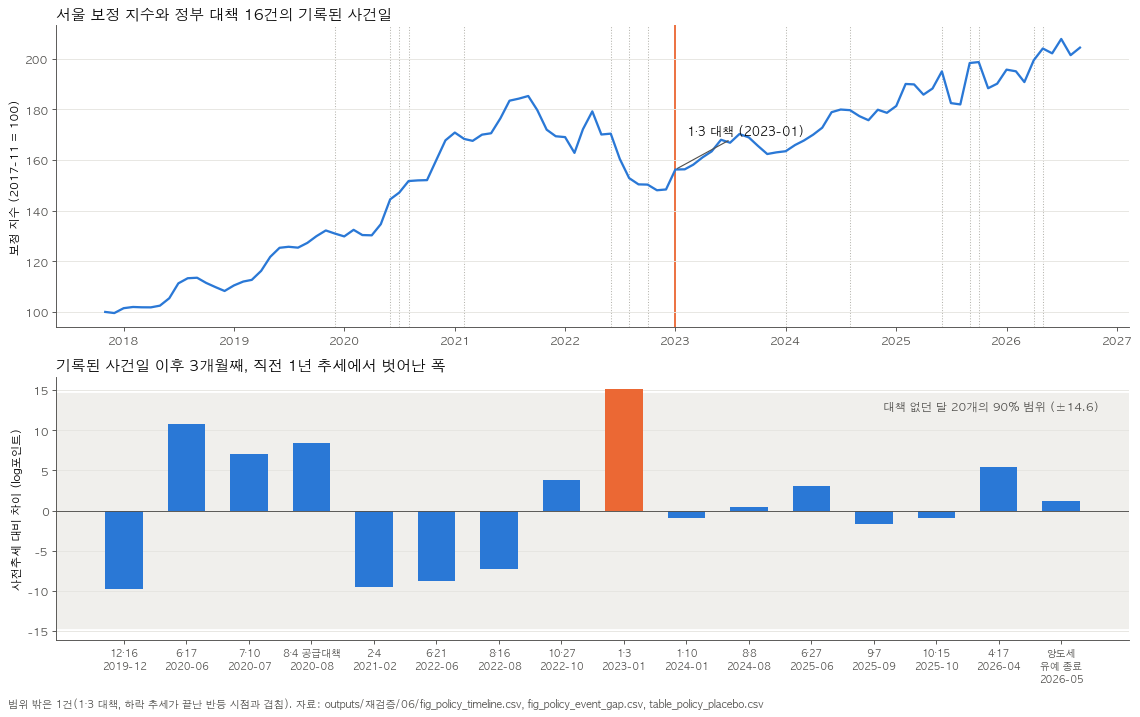

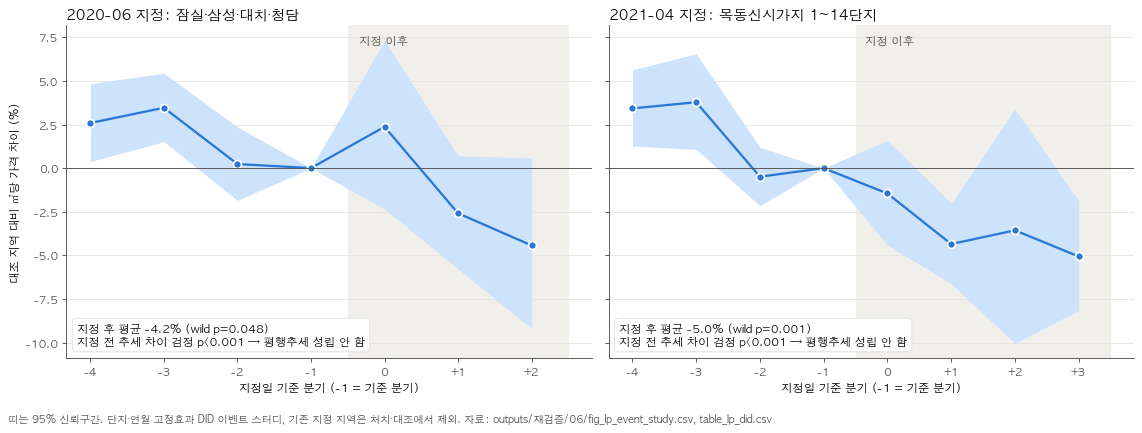

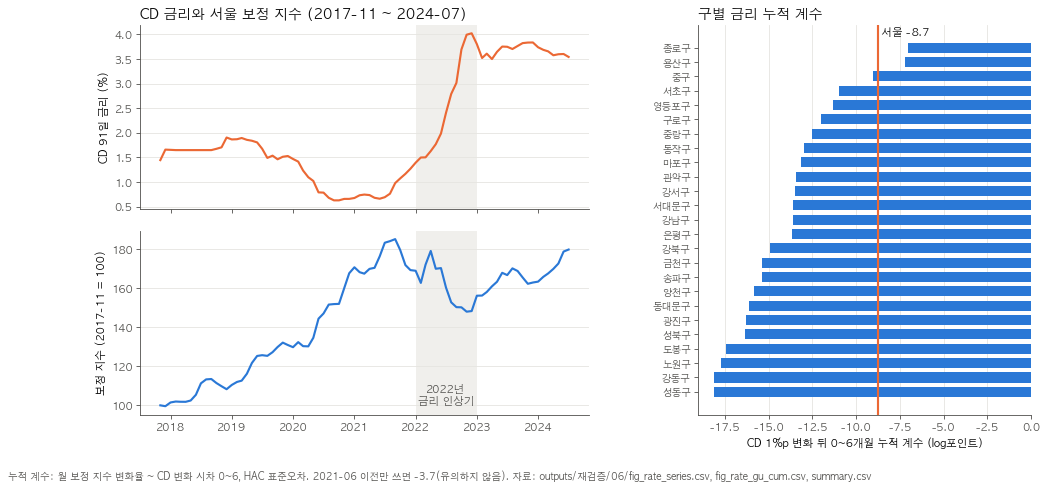

In [17]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager

_fonts = {f.name for f in font_manager.fontManager.ttflist}
for _name in ["AppleGothic", "NanumGothic", "Malgun Gothic"]:
    if _name in _fonts:
        plt.rcParams["font.family"] = _name
        break
plt.rcParams["axes.unicode_minus"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # 범주 색 고정 순서
INK, INK2, GRID, BAND = "#0b0b0b", "#52514e", "#e6e5e1", "#f0efec"


def style(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(INK2)
    ax.tick_params(colors=INK2)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def save(fig, name):
    """폭 1200px 이하 PNG로 저장하고 노트북에 표시한다(이 노트북은 Agg 백엔드라 plt.show()로는 보이지 않음)."""
    from IPython.display import Image, display
    w = fig.get_size_inches()[0]
    fig.savefig(OUT / name, dpi=min(110, 1150 / w), bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(OUT / name)))

OUT = ROOT / "outputs" / "재검증" / "06"
sm = pd.read_csv(OUT / "summary.csv").set_index("key")["value"]

# ① 정부 대책 시점과 사전추세 대비 차이
tl = pd.read_csv(OUT / "fig_policy_timeline.csv")
tl["date"] = pd.to_datetime(tl["month"])
gp = pd.read_csv(OUT / "fig_policy_event_gap.csv")
gp = gp[gp["event_id"].str.startswith("P") & gp["gap_logpt"].notna()].copy()
gp["date"] = pd.to_datetime(gp["month"])
plc = pd.read_csv(OUT / "table_policy_placebo.csv")
p90 = np.percentile(plc["gap_logpt"].abs(), 90)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(14, 8.5), gridspec_kw={"height_ratios": [1.15, 1]})
a1.plot(tl["date"], tl["index"], color=SERIES[0], lw=2)
for _, r in gp.iterrows():
    hit = bool(r["above_placebo_p90"])
    a1.axvline(r["date"], color=SERIES[1] if hit else "#b5b4ad", lw=1.6 if hit else 0.9, ls="-" if hit else ":", zorder=0)
hit = gp[gp["above_placebo_p90"].astype(bool)].iloc[0]
a1.annotate(f"{hit['name']} ({hit['month']})", (hit["date"], tl.set_index("month").loc[hit["month"], "index"]),
            xytext=(10, 30), textcoords="offset points", fontsize=10.5, color=INK, arrowprops=dict(arrowstyle="-", color=INK2))
a1.xaxis.set_major_locator(mdates.YearLocator())
a1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
a1.set_ylabel("보정 지수 (2017-11 = 100)")
a1.set_title(f"서울 보정 지수와 정부 대책 {len(gp)}건의 기록된 사건일", loc="left", fontsize=13, color=INK)
style(a1)

x = np.arange(len(gp))
a2.axhspan(-p90, p90, color=BAND, zorder=0)
a2.text(len(gp) - 0.4, p90 - 1, f"대책 없던 달 20개의 90% 범위 (±{p90:.1f})", ha="right", va="top", fontsize=10, color=INK2)
cols = [SERIES[1] if h else SERIES[0] for h in gp["above_placebo_p90"].astype(bool)]
a2.bar(x, gp["gap_logpt"], color=cols, width=0.6)
a2.axhline(0, color=INK2, lw=0.8)
a2.set_xticks(x, [f"{n}\n{m}" for n, m in zip(gp["name"].str.replace(" 대책", "").str.replace(" 가계부채 관리방안", "").str.replace("양도세 중과 유예 종료", "양도세\n유예 종료"), gp["month"])],
              fontsize=8.5)
a2.set_ylabel("사전추세 대비 차이 (log포인트)")
a2.set_title("기록된 사건일 이후 3개월째, 직전 1년 추세에서 벗어난 폭", loc="left", fontsize=13, color=INK)
style(a2)
fig.text(0.01, -0.02, f"범위 밖은 {int((gp['gap_logpt'].abs() > p90).sum())}건(1·3 대책, 하락 추세가 끝난 반등 시점과 겹침). "
         "자료: outputs/재검증/06/fig_policy_timeline.csv, fig_policy_event_gap.csv, table_policy_placebo.csv", fontsize=9, color=INK2)
fig.tight_layout()
save(fig, "viz_06_1_policy_gap.png")

# ② 토허제 두 사례 이벤트 스터디
es = pd.read_csv(OUT / "fig_lp_event_study.csv")
did = pd.read_csv(OUT / "table_lp_did.csv")
cases = [("L1", "2020-06 지정: 잠실·삼성·대치·청담"), ("L2-목동", "2021-04 지정: 목동신시가지 1~14단지")]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (ev, title) in zip(axes, cases):
    g = es[es["event"] == ev].sort_values("rel_q")
    r = did[(did["event"] == ev) & (did["type"] == "실제")].iloc[0]
    ax.axvspan(-0.5, g["rel_q"].max() + 0.5, color=BAND, zorder=0)
    ax.text(-0.35, 0.97, "지정 이후", transform=ax.get_xaxis_transform(), va="top", fontsize=10, color=INK2)
    ax.fill_between(g["rel_q"], g["ci_low_pct"], g["ci_high_pct"], color="#cde2fb", lw=0)
    ax.plot(g["rel_q"], g["coef_pct"], color=SERIES[0], lw=2, marker="o", ms=7, mec="white", mew=1.5)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(g["rel_q"], [f"{q:+d}" if q else "0" for q in g["rel_q"]])
    ax.set_xlabel("지정일 기준 분기 (-1 = 기준 분기)")
    ax.set_title(title, loc="left", fontsize=12.5, color=INK)
    ax.text(0.02, 0.04, f"지정 후 평균 {r['pct']:+.1f}% (wild p={r['wild_boot_p']:.3f})\n지정 전 추세 차이 검정 p<0.001 → 평행추세 성립 안 함" if r["pretrend_wald_p"] < 0.001 else f"지정 후 평균 {r['pct']:+.1f}% (wild p={r['wild_boot_p']:.3f})\n지정 전 추세 차이 검정 p={r['pretrend_wald_p']:.3f}",
            transform=ax.transAxes, fontsize=10, color=INK, bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=GRID))
    style(ax)
axes[0].set_ylabel("대조 지역 대비 ㎡당 가격 차이 (%)")
fig.text(0.01, -0.04, "띠는 95% 신뢰구간. 단지·연월 고정효과 DID 이벤트 스터디, 기존 지정 지역은 처치·대조에서 제외. "
         "자료: outputs/재검증/06/fig_lp_event_study.csv, table_lp_did.csv", fontsize=9, color=INK2)
fig.tight_layout()
save(fig, "viz_06_2_lp_cases.png")

# ③ 금리와 가격
rs = pd.read_csv(OUT / "fig_rate_series.csv")
rs["date"] = pd.to_datetime(rs["month"])
ix = tl[tl["month"] <= rs["month"].max()]
gu = pd.read_csv(OUT / "fig_rate_gu_cum.csv")
gu = gu[gu["level"] == "구"].sort_values("cum")
seoul = sm["rate_dl_cum_seoul_cd91"]

fig = plt.figure(figsize=(15, 6.6))
gs = fig.add_gridspec(2, 2, width_ratios=[1.35, 1], hspace=0.12, wspace=0.28)
b1 = fig.add_subplot(gs[0, 0]); b2 = fig.add_subplot(gs[1, 0], sharex=b1); b3 = fig.add_subplot(gs[:, 1])
for ax in (b1, b2):
    ax.axvspan(pd.Timestamp("2022-01"), pd.Timestamp("2023-01"), color=BAND, zorder=0, lw=0)
b1.plot(rs["date"], rs["cd91"], color=SERIES[1], lw=2)
b1.set_ylabel("CD 91일 금리 (%)")
b1.set_title("CD 금리와 서울 보정 지수 (2017-11 ~ 2024-07)", loc="left", fontsize=13, color=INK)
b2.text(pd.Timestamp("2022-07"), 0.04, "2022년\n금리 인상기", transform=b2.get_xaxis_transform(), ha="center", va="bottom", fontsize=10, color=INK2)
plt.setp(b1.get_xticklabels(), visible=False)
b2.plot(ix["date"], ix["index"], color=SERIES[0], lw=2)
b2.set_ylabel("보정 지수 (2017-11 = 100)")
b2.xaxis.set_major_locator(mdates.YearLocator())
b2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for ax in (b1, b2):
    style(ax)
b3.barh(gu["group"].str.replace("gu_", ""), gu["cum"], color=SERIES[0], height=0.7)
b3.axvline(seoul, color=SERIES[1], lw=2)
b3.text(seoul, len(gu) - 0.3, f" 서울 {seoul:.1f}", color=INK, fontsize=10, va="bottom")
b3.axvline(0, color=INK2, lw=0.8)
b3.set_xlabel("CD 1%p 변화 뒤 0~6개월 누적 계수 (log포인트)")
b3.set_title("구별 금리 누적 계수", loc="left", fontsize=13, color=INK)
b3.tick_params(axis="y", labelsize=9)
style(b3, grid="x")
fig.text(0.01, -0.02, f"누적 계수: 월 보정 지수 변화율 ~ CD 변화 시차 0~6, HAC 표준오차. 2021-06 이전만 쓰면 {sm['rate_dl_cum_seoul_cd91_pre2021_07']:.1f}(유의하지 않음). "
         "자료: outputs/재검증/06/fig_rate_series.csv, fig_rate_gu_cum.csv, summary.csv", fontsize=9, color=INK2)
save(fig, "viz_06_3_rate.png")
